---
title: "Economic Optimization of Customer Targeting"
subtitle: "Whom to contact, and at what cost"
jupyter: data-extraction-lesson
fig-width: 7
fig-height: 4.4
---

A score ranks customers by how likely they are to leave. A retention campaign asks a further question.

**Which customers should the company target so that the expected economic cost is as small as possible?**

Targeting a customer costs money. It can also change the probability that the customer leaves. The decision uses the cost, the loss if the customer leaves, and both probabilities (to leave with or without the campaign).



Run the cells from top to bottom.

## Stage 1 — From churn prediction to an economic decision

The previous workshop scored each **test** customer with a logistic regression that uses the structured fields and the communications. Those customers were not used to fit the model. This workshop treats that score as an input to a decision.

The scores are loaded from `SCORE_FILE`. They are not computed again. The previous workshop writes that file with `save_scores`. In the example, both workshops use `data/processed/telco/test_probabilities_with_text.csv`. For another dataset, set `SCORE_FILE` below to the path you used when saving, for example `data/processed/mydata/scores.csv`. The load uses that path.

For customer $i$:

| Symbol | Meaning |
|---|---|
| $p_{0,i}$ | Estimated probability of churn if customer $i$ is not targeted |
| $p_{1,i}$ | Estimated probability of churn if customer $i$ is targeted |
| $c_i$ | Cost of targeting customer $i$ |
| $L_i$ | Economic loss if customer $i$ churns |
| $a_i$ | 1 if customer $i$ is targeted, and 0 otherwise |

$p_{0,i}$ and $p_{1,i}$ are probabilities, so each one lies between 0 and 1. $c_i$ and $L_i$ are zero or positive. You can supply your own values. The telco file is only the working example.

The expected cost of a decision depends on the money at stake, not only on the churn probability.

## Stage 2 — The expected-cost problem

If the company targets customer $i$, it pays $c_i$. The probability of churn is then $p_{1,i}$, so the expected loss is $L_i p_{1,i}$.

If the company does not target customer $i$, it pays no contact cost. The probability of churn stays $p_{0,i}$, so the expected loss is $L_i p_{0,i}$.

One expression covers both choices:

$$
C_i(a_i) = c_i a_i + L_i\big[(1-a_i)p_{0,i} + a_i p_{1,i}\big].
$$

The first term is the contact cost. It is paid only when $a_i = 1$. The expression in brackets is the probability of churn under the choice you made. Multiply it by $L_i$ to get the expected loss.

The total expected cost is the sum over (test) customers:

$$
J(a_1,\ldots,a_n) = \sum_i C_i(a_i).
$$

The problem is:

$$
\text{minimize } J(a_1,\ldots,a_n)
\quad\text{subject to}\quad
a_i \in \{0,1\}
\text{ for every customer } i.
$$

The solution is a list $a^\star = (a_1^\star,\ldots,a_n^\star)$. Target customer $i$ when $a_i^\star = 1$. Do not target customer $i$ when $a_i^\star = 0$.

The total is a sum of separate customer costs, so the choice for one customer does not change the arithmetic for another. Compare the two options for each customer:

- Expected cost with no campaign: $L_i p_{0,i}$.
- Expected cost with a campaign: $c_i + L_i p_{1,i}$.

Target customer $i$ when the second amount is smaller. Rearrangement gives the same rule:

$$
L_i(p_{0,i} - p_{1,i}) > c_i.
$$

$L_i(p_{0,i} - p_{1,i})$ is the expected loss avoided by the campaign. Target customer $i$ if the expected loss avoided exceeds the campaign cost.

The expected net benefit is that comparison, written as one number:

$$
b_i = L_i(p_{0,i} - p_{1,i}) - c_i.
$$

Target customer $i$ when $b_i > 0$.

Three customers make the arithmetic concrete. The contact cost is 15 in each row.

| Customer | $p_0$ | $p_1$ | $L$ | Cost if not targeted | Cost if targeted | $b$ | Decision |
|---|---:|---:|---:|---:|---:|---:|---|
| A | 0.10 | 0.08 | 200 | 20 | 31 | −11 | do not target |
| B | 0.55 | 0.20 | 500 | 275 | 115 | 160 | target |
| C | 0.80 | 0.75 | 100 | 80 | 90 | −10 | do not target |

Customer C has the highest churn probability. The campaign lowers that probability by only 0.05, and the loss is 100, so the expected loss avoided is 5. The contact costs 15. C is not targeted.

## Stage 3 — The individual decision

The calculation is the function `allocate`. It accepts one number for every customer, or a list with one entry per customer. A table version, `allocate_frame`, reads columns whose names you choose.

The inputs must agree in length. A probability outside 0 to 1, a negative cost, or a negative loss stops the calculation. A missing value stops it as well: the function does not fill one in. Every decision it returns is 0 or 1.

In [1]:
from pathlib import Path
import os
import sys

import numpy as np
import pandas as pd

# Folder and file name of the scores written by save_scores in the previous workshop.
# For another dataset, set the same path you used there, for example:
# SCORE_FILE = "data/processed/mydata/scores.csv"
SCORE_FILE = "data/processed/telco/test_probabilities_with_text.csv"
POPULATION_FILE = "data/processed/telco/campaign_example_population.csv"
# Test customers only. Chapter 7 reloads this path as ECONOMICS_FILE.
# Columns used there: p1, example_cost, example_loss. Fit rows are not in this file.

if not Path(SCORE_FILE).exists():
    os.chdir(Path("..").resolve())
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import python.workshop_targeting as targeting

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")

`read_scores` loads the file written by `save_scores`. It requires `customer_id`, `p0` and `observed_outcome`. `p0` is the score. `observed_outcome` is 1 when the customer churned and 0 otherwise.

In [2]:
scores = targeting.read_scores(SCORE_FILE)
print(f"{len(scores)} customers in {SCORE_FILE}.")
scores.head()

1761 customers in data/processed/telco/test_probabilities_with_text.csv.


,customer_id,p0,observed_outcome
0,5343-SGUBI,0.198,0
1,5442-BXVND,0.067,0
2,6434-TTGJP,0.065,0
3,1628-BIZYP,0.845,0
4,0298-XACET,0.029,0


The same three customers, passed as lists. `cost` is one number, so every customer has the same contact cost. `loss` is one number per customer.

In [3]:
vector_plan = targeting.allocate(
    p0=[0.10, 0.55, 0.80],
    p1=[0.08, 0.20, 0.75],
    cost=15,
    loss=[200, 500, 100],
    ids=["A", "B", "C"],
)
targeting.customer_table(vector_plan)

,row,id,p0,p1,cost,loss,expected_cost_without,expected_cost_with_campaign,net_benefit,target
0,1,A,0.100,0.080,15.000,200.000,20.000,31.000,-11.000,0
1,2,B,0.550,0.200,15.000,500.000,275.000,115.000,160.000,1
2,3,C,0.800,0.750,15.000,100.000,80.000,90.000,-10.000,0


The same inputs can sit in a table. The column names are yours. They do not have to be `p0` or `loss`.

In [4]:
records = pd.DataFrame({
    "customer": ["A", "B", "C"],
    "chance_without": [0.10, 0.55, 0.80],
    "chance_with": [0.08, 0.20, 0.75],
    "contact_cost": [15, 15, 15],
    "churn_loss": [200, 500, 100],
})
frame_plan = targeting.allocate_frame(
    records,
    p0="chance_without",
    p1="chance_with",
    cost="contact_cost",
    loss="churn_loss",
    id_column="customer",
)
print("Same decisions as the lists:", np.array_equal(frame_plan["target"], vector_plan["target"]))

Same decisions as the lists: True


`allocate` also returns the totals: the expected cost of the plan, the contact spending, the number and share of customers targeted, and the expected benefit relative to doing nothing. The benefit equals the expected cost of doing nothing minus the expected cost of the plan.

In [5]:
targeting.compare({"Three customers": vector_plan})

,Plan,Customers targeted,Share targeted,Campaign spend,Expected cost,Benefit vs no campaign
0,Three customers,1,0.333,15.000,215.000,160.000


### The telco test customers

`POPULATION_FILE` is the campaign table of these test customers. `p1` is the probability of staying if contacted. `example_cost` is the contact cost. `example_loss` is the loss if the customer leaves. Fit rows are not in the file. Chapter 7 reads the same path as `ECONOMICS_FILE`.

The scores were loaded above. This example attaches a campaign probability, a contact cost and a loss. With your own score file, replace those three inputs. The column names in the example are not required by the functions.

The example loss is twelve times the customer's current monthly charge. The example contact cost is 30, 45, or 180. Both are assumptions.

::: callout-note
For this exercise, campaign probabilities are simulated. In a real application, they would need to be estimated using suitable campaign data, ideally from a randomized experiment.
:::

In [6]:
example = targeting.read_population(POPULATION_FILE)
same_customers = scores["customer_id"].tolist() == example["customer_id"].tolist()
same_scores = np.allclose(scores["p0"], example["p0"])
if not (same_customers and same_scores):
    raise targeting.TargetingError(
        "The campaign table does not match the scores loaded from SCORE_FILE."
    )

p0 = scores["p0"].to_numpy()
p1 = example["p1"].to_numpy()
cost = example["example_cost"].to_numpy()
loss = example["example_loss"].to_numpy()
customer_ids = scores["customer_id"].tolist()
observed = scores["observed_outcome"].to_numpy()

There is no shared probability cutoff in this calculation. Each customer is compared with that customer's own cost, loss, and campaign probability. Two customers with the same `p0` can receive different decisions.

In [7]:
plan = targeting.allocate(p0, p1, cost, loss, ids=customer_ids)
targeting.compare({"No shared budget": plan})

,Plan,Customers targeted,Share targeted,Campaign spend,Expected cost,Benefit vs no campaign
0,No shared budget,948,0.538,36795.000,476738.506,114991.691


In [8]:
targeting.selected_customers(plan, limit=8)

,row,id,p0,p1,cost,loss,expected_cost_without,expected_cost_with_campaign,net_benefit,target
0,100,9221-OTIVJ,0.958,0.510,45.000,1258.200,1205.233,686.416,518.817,1
1,1085,5052-PNLOS,0.964,0.537,30.000,1264.200,1218.713,708.792,509.921,1
2,1619,5419-CONWX,0.956,0.499,45.000,1197.600,1145.086,642.615,502.471,1
3,876,1400-MMYXY,0.960,0.534,45.000,1270.800,1220.395,723.512,496.883,1
4,6,8245-UMPYT,0.950,0.502,45.000,1156.800,1099.420,625.275,474.145,1
5,1034,8059-UDZFY,0.875,0.481,45.000,1264.200,1105.564,652.764,452.799,1
6,1326,7029-RPUAV,0.913,0.510,45.000,1205.400,1100.364,659.878,440.485,1
7,1143,3992-YWPKO,0.900,0.543,30.000,1318.800,1186.896,746.555,440.341,1


The historical churn label is still on the file (just for information, for current customers, that obviously would not be known). It is not used to compute the expected cost.

In [9]:
chosen = plan["target"] == 1
pd.DataFrame({
    "Group": ["Targeted", "Not targeted"],
    "Customers": [int(chosen.sum()), int((~chosen).sum())],
    "Observed churn rate": [observed[chosen].mean(), observed[~chosen].mean()],
})

,Group,Customers,Observed churn rate
0,Targeted,948,0.439
1,Not targeted,813,0.063


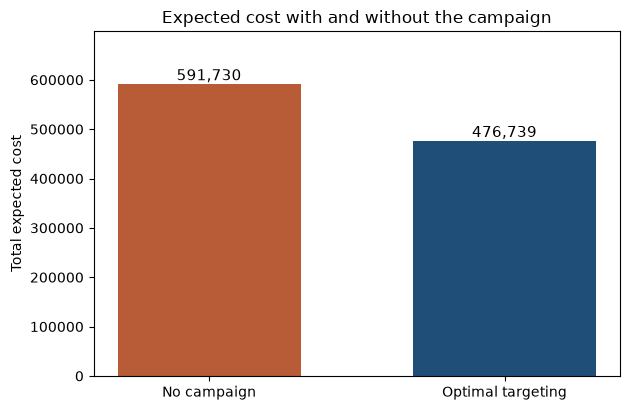

In [10]:
targeting.plot_expected_costs(plan)

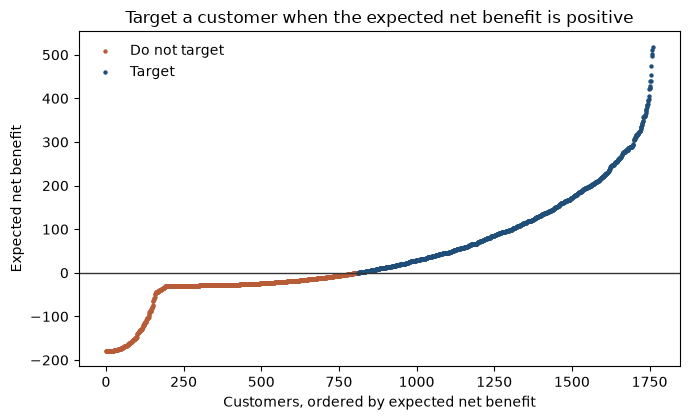

In [11]:
targeting.plot_net_benefits(plan)

The horizontal line is zero. Customers above it are targeted. Customers on or below it are not.

## Stage 4 — When the decision is a probability cutoff

Impose three extra restrictions:

- $c_i = c$ for every customer;
- $L_i = L$ for every customer;
- $p_{1,i} = (1-r)p_{0,i}$, with the same effectiveness $r$ for every customer.

Then $p_{0,i} - p_{1,i} = r p_{0,i}$, and the expected net benefit becomes

$$
b_i = r L p_{0,i} - c.
$$

Target customer $i$ when $b_i > 0$. With $r$ and $L$ positive, that is the same statement as

$$
p_{0,i} > \frac{c}{r L}.
$$

The cutoff is therefore

$$
t^\star = \frac{c}{r L}.
$$

$t^\star$ is a consequence of the cost calculation. It appears only when the contact cost, the loss, and the campaign effectiveness are each the same for every customer. Outside those three restrictions, the rule remains the customer-level comparison in Stage 3.

In [12]:
EFFECTIVENESS = 0.25
COMMON_COST = 40
COMMON_LOSS = 600

p1_common = targeting.campaign_probabilities(p0, EFFECTIVENESS)
common_plan = targeting.allocate(p0, p1_common, COMMON_COST, COMMON_LOSS, ids=customer_ids)
cutoff = targeting.probability_threshold(COMMON_COST, COMMON_LOSS, EFFECTIVENESS)
by_cutoff = (p0 > cutoff).astype(int)
print(f"Cutoff t* = {cutoff:.3f}.")
print(f"Decisions on which the cost rule and the cutoff disagree: {int(np.sum(common_plan['target'] != by_cutoff))}.")
targeting.compare({"Common cost, loss and effectiveness": common_plan})

Cutoff t* = 0.267.
Decisions on which the cost rule and the cutoff disagree: 0.


,Plan,Customers targeted,Share targeted,Campaign spend,Expected cost,Benefit vs no campaign
0,"Common cost, loss and effectiveness",937,0.532,37480.000,351376.607,51946.038


Ranking customers by the churn probability alone can select the wrong people: Telco customers in Stage 3 are one such case: costs, losses, and campaign probabilities all differ. 


## Stage 5 — A limited campaign budget

A budget $B$ limits total contact spending:

$$
\begin{aligned}
\text{minimize } &\sum_i \Big(c_i a_i + L_i\big[(1-a_i)p_{0,i} + a_i p_{1,i}\big]\Big) \\
\text{subject to } &\sum_i c_i a_i \le B, \\
&a_i \in \{0,1\}.
\end{aligned}
$$

The expected cost of a plan can be rewritten as

$$
J(a) = \sum_i L_i p_{0,i} - \sum_i b_i a_i.
$$

The first sum is the expected cost of targeting nobody. It does not depend on the decision. Minimising $J$ under the budget is therefore the same problem as maximising the total expected net benefit, $\sum_i b_i a_i$, under the same budget.

A customer with $b_i \le 0$ is never selected. Targeting that customer would raise expected cost, and it would use budget.

### Equal contact costs

Suppose every contact costs the same amount $c$, and $c > 0$. The budget can pay for at most

$$
K = \lfloor B / c \rfloor
$$

customers. The solution is then the $K$ customers with the largest positive expected net benefits. If fewer than $K$ customers have a positive benefit, target only those.

The cell below keeps the simulated campaign probabilities, so effectiveness still differs across customers. The contact cost is 40 and the loss is 600 for every customer. The budget pays for at most 200 contacts.

In [13]:
COMMON_COST = 40
COMMON_LOSS = 600
MAX_CUSTOMERS = 200
equal_budget = COMMON_COST * MAX_CUSTOMERS

open_equal = targeting.allocate(p0, p1, COMMON_COST, COMMON_LOSS, ids=customer_ids)
equal_plan = targeting.allocate_under_equal_cost(
    p0, p1, COMMON_COST, COMMON_LOSS, equal_budget, ids=customer_ids
)
targeting.compare({
    "No customer limit": open_equal,
    f"At most {MAX_CUSTOMERS} customers": equal_plan,
})

,Plan,Customers targeted,Share targeted,Campaign spend,Expected cost,Benefit vs no campaign,Budget,Within budget
0,No customer limit,906,0.514,36240.000,336722.762,66599.883,,
1,At most 200 customers,200,0.114,8000.000,372625.835,30696.810,8000.000,Yes


Because effectiveness differs, the largest churn probabilities are not the largest expected net benefits.

In [14]:
highest_probability = np.zeros(len(p0), dtype=int)
highest_probability[np.argsort(-p0)[:MAX_CUSTOMERS]] = 1
differ = int(np.sum(highest_probability != equal_plan["target"]))
print(
    f"The {MAX_CUSTOMERS} highest churn probabilities and this budget rule "
    f"differ for {differ} customers."
)

The 200 highest churn probabilities and this budget rule differ for 190 customers.


### Contact costs that differ

When contact costs differ, filling the budget with the largest net benefits can be the wrong set. One expensive customer can crowd out several cheaper customers whose benefits add up to more.

Three customers and a budget of 6 show the arithmetic. The losses and probabilities below produce expected net benefits of 6, 5, and 5. The contact costs are 4, 3, and 3.

Taking the benefit of 6 spends 4 and leaves 2, which pays for nobody else. The total benefit is 6. Taking the two benefits of 5 spends 6. The total benefit is 10.

In [15]:
small_exact = targeting.allocate_under_budget(
    p0=[1.00, 0.80, 0.80],
    p1=[0.00, 0.00, 0.00],
    cost=[4, 3, 3],
    loss=10,
    budget=6,
    ids=["High benefit", "Lower benefit 1", "Lower benefit 2"],
    mode="RUN",
)
small_ranked = targeting.allocate_by_benefit_rank(
    p0=[1.00, 0.80, 0.80],
    p1=[0.00, 0.00, 0.00],
    cost=[4, 3, 3],
    loss=10,
    budget=6,
    ids=["High benefit", "Lower benefit 1", "Lower benefit 2"],
)
targeting.compare({
    "Exact budget solution": small_exact,
    "Largest benefits first": small_ranked,
})

,Plan,Customers targeted,Share targeted,Campaign spend,Expected cost,Benefit vs no campaign,Budget,Within budget
0,Exact budget solution,2,0.667,6.000,16.000,10.000,6.000,Yes
1,Largest benefits first,1,0.333,4.000,20.000,6.000,6.000,Yes


The telco example uses the customer-specific costs and losses from Stage 3. The budget is 8000. `allocate_under_budget` solves the binary problem exactly. `allocate_by_benefit_rank` is the ranking rule, shown only for comparison.

On this file the exact solve takes about half a second, so the default mode is `"RUN"`. `"SAVE"` stores the solution. `"LOAD"` reads a stored solution and stops if the inputs or the budget differ from the saved run. It does not invent a result.

In [16]:
BUDGET = 8000

targeting.OPTIMIZATION_MODE = "RUN"
# targeting.OPTIMIZATION_MODE = "SAVE"
# targeting.OPTIMIZATION_MODE = "LOAD"

budget_plan = targeting.allocate_under_budget(
    p0, p1, cost, loss, BUDGET, ids=customer_ids
)
ranked_plan = targeting.allocate_by_benefit_rank(
    p0, p1, cost, loss, BUDGET, ids=customer_ids
)
targeting.compare({
    "No budget": plan,
    "Exact budget solution": budget_plan,
    "Largest benefits first": ranked_plan,
})

,Plan,Customers targeted,Share targeted,Campaign spend,Expected cost,Benefit vs no campaign,Budget,Within budget
0,No budget,948,0.538,36795.000,476738.506,114991.691,,
1,Exact budget solution,242,0.137,7995.000,528769.429,62960.767,8000.000,Yes
2,Largest benefits first,210,0.119,7980.000,533229.027,58501.169,8000.000,Yes


In [17]:
gap = budget_plan["benefit"] - ranked_plan["benefit"]
if gap > 1:
    print(f"Ranking by expected net benefit leaves {gap:,.0f} of expected benefit unused.")
else:
    print("For this budget, the ranking rule and the exact solution select the same customers.")
print(f"Exact spend {budget_plan['campaign_spend']:,.0f} is within the budget of {BUDGET:,.0f}.")

Ranking by expected net benefit leaves 4,460 of expected benefit unused.
Exact spend 7,995 is within the budget of 8,000.


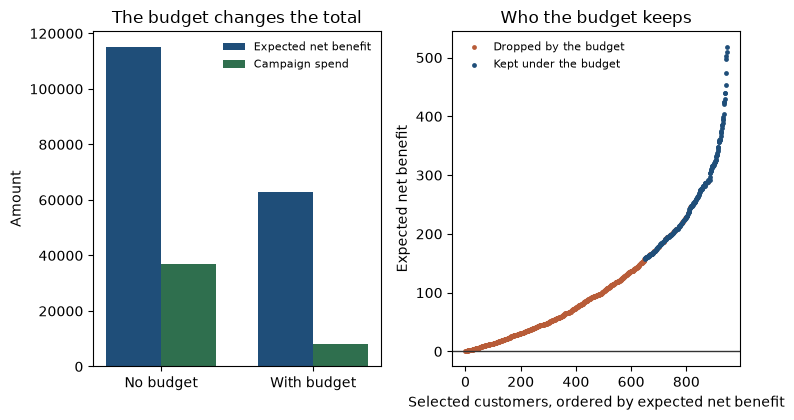

In [18]:
targeting.plot_allocations(plan, budget_plan)

The left panel compares spending and expected net benefit. The right panel shows who would be targeted with no budget. The legend marks who the budget keeps and who it drops.

## Stage 6 — Change the economic assumptions

A decision can change when a cost, a loss, a campaign probability, or the budget changes. Edit the four assignments and run the cell again. The defaults reproduce the plan from Stage 3 and the budget from Stage 5.

`REDUCTION_SCALE` multiplies the gap between `p0` and the simulated `p1`. A scale of 1 keeps the example. A scale of 0 means the campaign changes no probability. Keep the scale between 0 and 1 so that every campaign probability stays between 0 and 1.

In [19]:
COST_MULTIPLIER = 1.0
LOSS_MULTIPLIER = 1.0
REDUCTION_SCALE = 1.0
BUDGET = 8000

cost_now = cost * COST_MULTIPLIER
loss_now = loss * LOSS_MULTIPLIER
p1_now = p0 - REDUCTION_SCALE * (p0 - p1)
revised = targeting.allocate(p0, p1_now, cost_now, loss_now, ids=customer_ids)
revised_budget = targeting.allocate_under_budget(
    p0, p1_now, cost_now, loss_now, BUDGET, ids=customer_ids, mode="RUN"
)
targeting.compare({"No budget": revised, "With budget": revised_budget})

,Plan,Customers targeted,Share targeted,Campaign spend,Expected cost,Benefit vs no campaign,Budget,Within budget
0,No budget,948,0.538,36795.000,476738.506,114991.691,,
1,With budget,242,0.137,7995.000,528769.429,62960.767,8000.000,Yes


The next table changes one thing only: the common campaign effectiveness $r$, with $p_{1,i} = (1-r)p_{0,i}$. Like in Section 6.5.1, the contact cost is 40, the loss is 600 and the budget pays for at most 200 contacts.

In [20]:
sensitivity = targeting.effectiveness_sensitivity(
    p0,
    cost=40,
    loss=600,
    effectiveness=[0.10, 0.20, 0.30, 0.50, 0.70],
    budget=40 * 200,
)
sensitivity

,effectiveness,customers_targeted,share_targeted,campaign_spend,expected_cost,benefit_vs_no_campaign,threshold,budget_customers_targeted,budget_campaign_spend,budget_expected_cost,budget_benefit_vs_no_campaign,decisions_changed
0,0.100,439,0.249,17560.000,398831.603,4491.042,0.667,200,8000.000,400267.073,3055.572,0
1,0.200,839,0.476,33560.000,368848.914,34473.731,0.333,200,8000.000,389211.501,14111.143,400
2,0.300,999,0.567,39960.000,333259.335,70063.309,0.222,200,8000.000,378155.930,25166.715,160
3,0.500,1184,0.672,47360.000,257563.335,145759.310,0.133,200,8000.000,356044.786,47277.859,185
4,0.700,1275,0.724,51000.000,179595.701,223726.944,0.095,200,8000.000,333933.643,69389.002,91


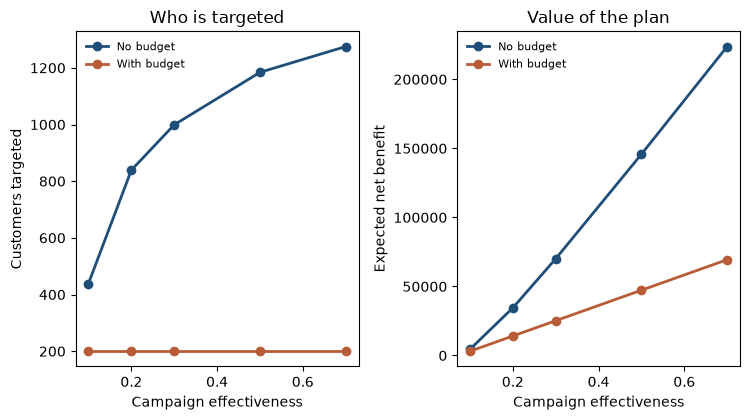

In [21]:
targeting.plot_effectiveness(sensitivity)

As $r$ rises, the unconstrained plan targets more customers and the cutoff $t^\star = c/(rL)$ falls. `decisions_changed` counts those changes from one row to the next.

The budget plan stays at 200 customers. Under a common cost, a common loss, and a common effectiveness, expected net benefit ranks customers in the same order as $p_0$. The 200 contacts are the 200 highest churn probabilities among customers with a positive benefit. That set does not change across these rows, because more than 200 customers already have a positive benefit at $r = 0.10$. The expected benefit of the budget plan still rises: the same contacts avoid more expected loss when the campaign is more effective.

## Stage 7 — Campaign probabilities from real campaign data

$p_{1,i}$ was supplied to this workshop. A real campaign file would have to produce it.

A model fitted on customers who were offered the campaign can estimate the churn probability under the campaign, for customers who look like them.

That estimate is not yet the effect of the campaign. The effect is the difference between the outcome with the campaign and the outcome that would have occurred without it.

A randomized control group provides the comparison. Customers who were not offered the campaign identify $p_{0,i}$. Customers who were offered it identify $p_{1,i}$. Under a properly run randomization, the difference is the causal effect of the campaign.

A file that contains only customers who received the campaign does not identify what they would have done without it.

The telco file has no campaign indicator and no random assignment. It cannot estimate campaign effectiveness.

Uplift is the name for the difference in probabilities:

$$
u_i = p_{0,i} - p_{1,i}.
$$

The expected net benefit is then

$$
b_i = L_i u_i - c_i.
$$

The first customer to consider is the one with the highest positive expected net benefit. The budget decides whether that customer is affordable, and which affordable group has the largest total benefit. A high churn probability does not settle the choice. This workshop does not fit an uplift model.

## Test customers, and customers the model has already seen

The scores in this workshop are the test customers from the previous one. The model did not use those rows when it chose the coefficients. They stand in for customers the model has not seen.

They are still a slice of the same historical file. The churn on those rows has already happened. They are a stand-in for a current book, not the current book itself.

The same coefficients can be applied to every row of the file, including the rows that were used to fit the model. That produces a score for the whole file.

- On a customer the model did not see, the score is the kind of number the test set is meant to give. The outcome did not help choose the coefficients.
- On a customer who was used to fit the model, the outcome did help choose the coefficients. The score is pulled toward a result the model has already seen. It will look more accurate than a score on a new customer.

The observed outcome splits in the same way. On the test rows, it was not used to choose the coefficients. On the training rows, it was. Using those training rows as a check of the score mixes the past fit with the customers still to be decided about.

Keep the two groups apart. Fit on the past. Score the customers you might contact now. When the only available file is the historical one, use the test rows as the campaign table and leave the training rows out of it.

## Run the workshop

Run the cells from top to bottom. From the project folder:

```bash
quarto render lessons/02f-campaign-targeting.qmd
```

The render reads the file named in `SCORE_FILE`. It does not fit the logistic regression again. For another dataset, set `SCORE_FILE` to the path used when those scores were saved, for example `data/processed/mydata/scores.csv`.